# Oversampling

### <i> Using duplicates + noise generation

We can consider this as a "bare-bones" oversampling attempt. Usually we prefer actualy data synthetization algorithms instead (SMOTE + algorithms in SDV)

This uses the possum-dataset (extra dataset not used in exercise project 1).

In [ ]:
# pip install imblearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Loading dataframe
df = pd.read_csv(
    "../possum.csv",
    index_col=0
)

# Set the index (could do this while making the dataframe too I suppose. )
df = df.set_index("case")

# Simplifying the dataset by dropping some columns.
df = df.drop(["hdlngth", "skullw", "totlngth", "taill", "footlgth"], axis=1)
df


,site,Pop,sex,age,earconch,eye,chest,belly
case,,,,,,,,
1,1,Vic,m,8.0,54.5,15.2,28.0,36.0
2,1,Vic,f,6.0,51.2,16.0,28.5,33.0
3,1,Vic,f,6.0,51.9,15.5,30.0,34.0
4,1,Vic,f,6.0,52.2,15.2,28.0,34.0
5,1,Vic,f,2.0,53.2,15.1,28.5,33.0
...,...,...,...,...,...,...,...,...
15659814,1,other,m,4.0,48.5,14.9,26.5,37.2
119405,6,Vic,m,3.0,49.9,14.1,27.3,33.9
14131878,6,Vic,m,6.0,43.4,16.4,28.1,40.0


In [2]:
import numpy as np
import pandas as pd


'''
This is a VERY simple which function synthesizes new rows by taking random rows from the given
dataframe. It then changes the continuous column values of these new rows such that
the `noise_factor` is multiplied by the original column's standard deviation!
NOTE: You can't make `n_samples` a higher number than the dataframe's row count!

df = pandas.dataframe
n_samples = int
continuous_columns = list of column names
noise_factor = float 
'''
def noisy_augmentation(df, n_samples, continuous_columns, noise_factor=0.05):

    # Randomly duplicate rows
    synthetic = df.sample(n=n_samples,replace=True).copy()

    # Add Gaussian noise to selected columns
    for column in continuous_columns:
        noise = np.random.normal(0, df[column].std() * noise_factor, n_samples)
        synthetic[column] += noise

    return synthetic


### How to use it!

In [3]:
# Say we want to make more victorian males! Let's make a filter for that
filter = df[
    (df["Pop"] == "Vic") &
    (df["sex"] == "m")
]

# Then we use the function.
synthetic_df = noisy_augmentation(
    filter,
    n_samples=100,
    continuous_columns=["age", "earconch", "eye", "chest","belly"]
)

synthetic_df = synthetic_df.reset_index(drop=True)
synthetic_df

,site,Pop,sex,age,earconch,eye,chest,belly
0,2,Vic,m,1.920514,56.222675,14.532127,26.081288,32.825946
1,2,Vic,m,2.897258,44.310869,15.643282,24.705037,36.501783
2,1,Vic,m,2.985751,46.956679,14.590335,27.972852,38.656931
3,1,Vic,m,2.088266,44.890194,14.049355,22.669085,33.801174
4,1,Vic,m,4.135383,54.273523,13.279080,23.616630,33.406193
...,...,...,...,...,...,...,...,...
95,1,Vic,m,1.961501,45.714917,15.159203,29.581365,32.145643
96,7,Vic,m,1.028896,42.582293,17.586605,25.063900,34.378939
97,2,Vic,m,6.106518,48.552031,16.213287,26.308116,37.624895
98,4,Vic,m,3.061375,43.689582,12.834220,28.949661,39.512245


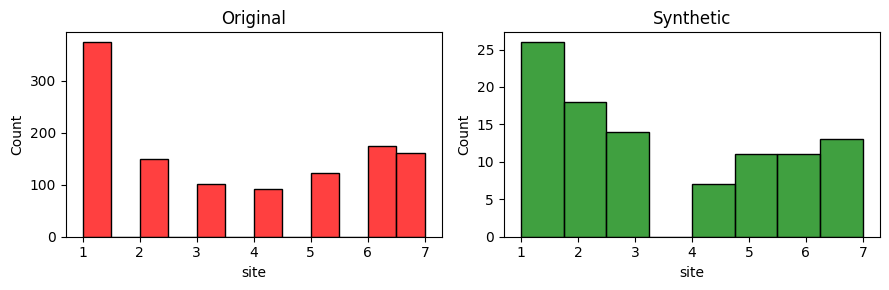

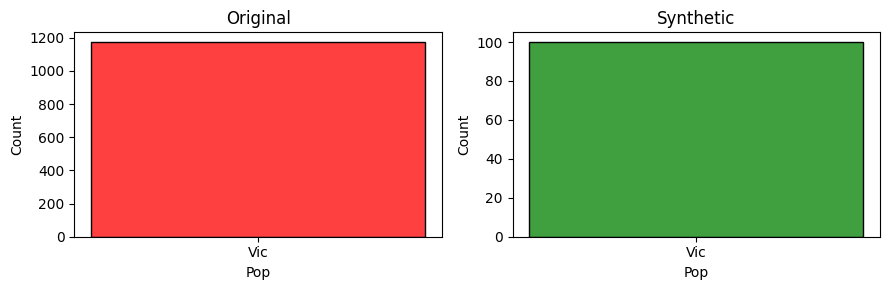

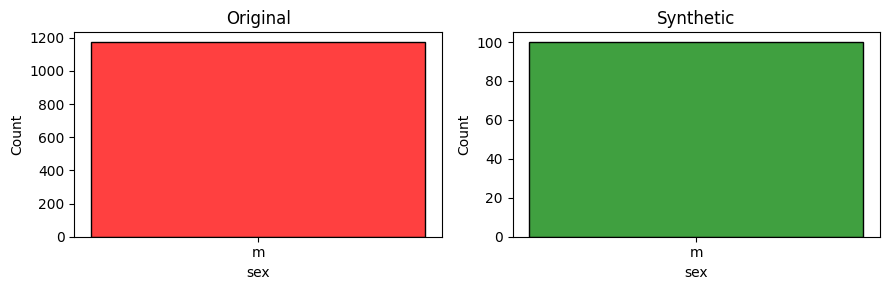

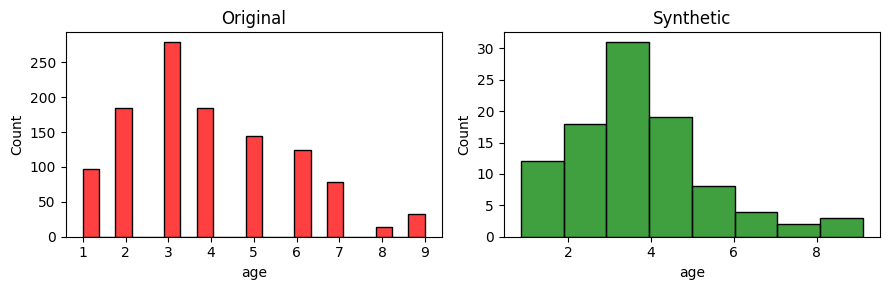

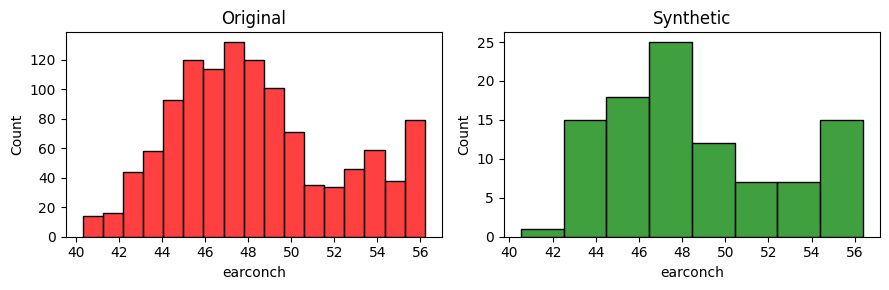

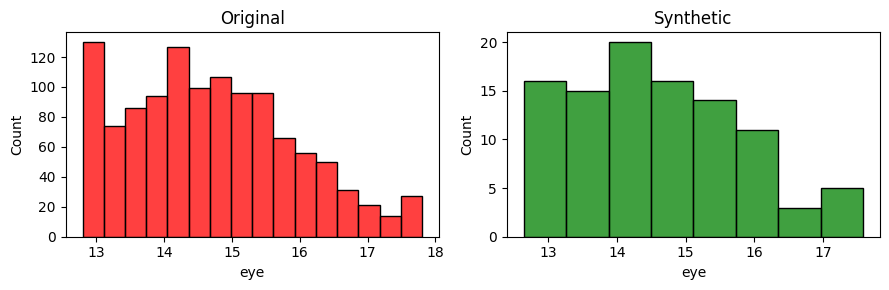

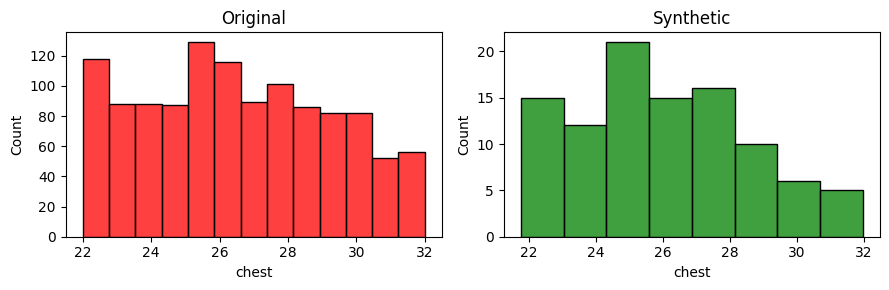

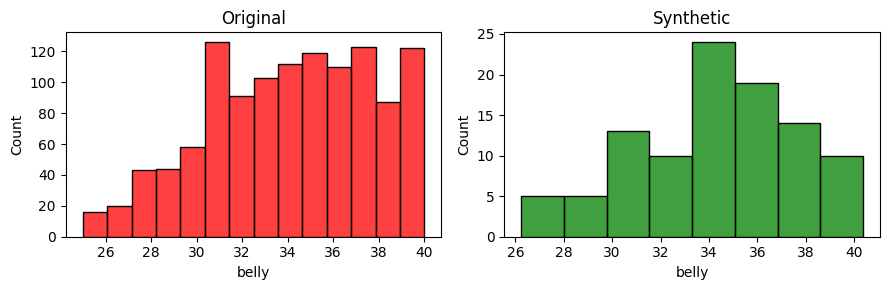

In [4]:

# Now we visualize the result. Are we happy with the result?
columns = synthetic_df.columns

for column in columns:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))

    sns.histplot(filter, x=column,ax=axes[0], color="red")
    sns.histplot(synthetic_df, x=column,ax=axes[1], color="green")

    axes[0].set_title("Original")
    axes[1].set_title("Synthetic")

    # Prevents overlap between graphs
    plt.tight_layout()

    # Shows the plots
    plt.show()

# It's... not quite perfect, but it's undeniably fitting reasonably well!

In [5]:
# Placing the new rows into our original df
df_combined = pd.concat([df, synthetic_df])
df

,site,Pop,sex,age,earconch,eye,chest,belly
case,,,,,,,,
1,1,Vic,m,8.0,54.5,15.2,28.0,36.0
2,1,Vic,f,6.0,51.2,16.0,28.5,33.0
3,1,Vic,f,6.0,51.9,15.5,30.0,34.0
4,1,Vic,f,6.0,52.2,15.2,28.0,34.0
5,1,Vic,f,2.0,53.2,15.1,28.5,33.0
...,...,...,...,...,...,...,...,...
15659814,1,other,m,4.0,48.5,14.9,26.5,37.2
119405,6,Vic,m,3.0,49.9,14.1,27.3,33.9
14131878,6,Vic,m,6.0,43.4,16.4,28.1,40.0


In [6]:
# Let's check the original filter's statistics
filter.describe()

,site,age,earconch,eye,chest,belly
count,1174.000000,1141.000000,1174.000000,1174.000000,1174.000000,1174.000000
mean,3.516184,3.919369,48.350085,14.694293,26.542589,34.146593
std,2.271284,1.934131,3.815026,1.220600,2.754287,3.652562
min,1.000000,1.000000,40.300000,12.800000,22.000000,25.000000
25%,1.000000,3.000000,45.500000,13.800000,24.325000,31.300000
50%,3.000000,4.000000,47.700000,14.600000,26.350000,34.400000
75%,6.000000,5.000000,50.500000,15.500000,28.700000,37.100000
max,7.000000,9.000000,56.200000,17.800000,32.000000,40.000000


In [7]:
# And let's compare it with the synthetic statistics.
synthetic_df.describe()

,site,age,earconch,eye,chest,belly
count,100.000000,97.000000,100.000000,100.000000,100.000000,100.000000
mean,3.440000,3.582280,48.579586,14.602875,25.967404,34.373837
std,2.157065,1.781194,4.090691,1.254755,2.648127,3.393738
min,1.000000,0.863191,40.531194,12.641424,21.750015,26.244791
25%,1.000000,2.109804,45.015238,13.657464,23.653854,32.012765
50%,3.000000,3.074917,47.894044,14.480313,25.702674,34.530806
75%,5.000000,4.754540,51.360640,15.571118,27.953271,36.742542
max,7.000000,9.115274,56.372585,17.586605,31.980073,40.367440


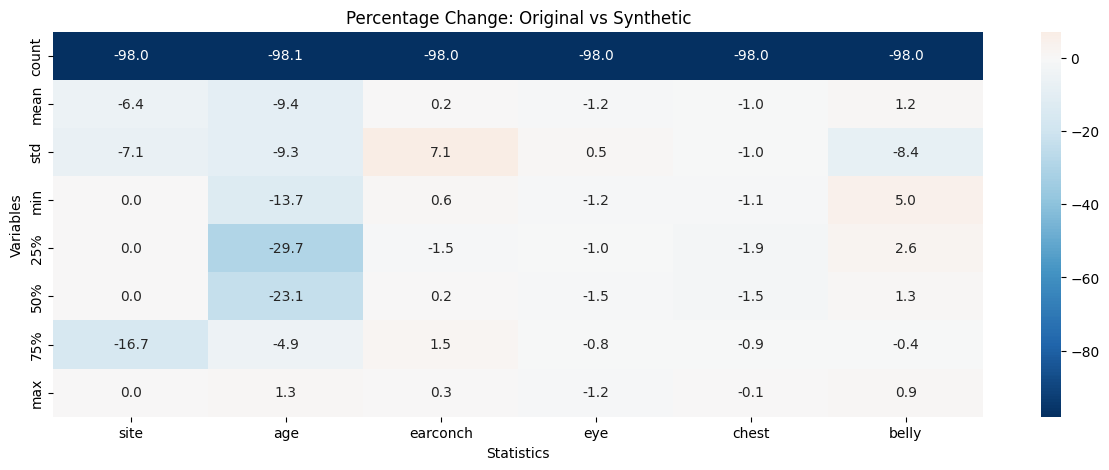

In [ ]:
# Let's use a heatmap to tell us what's different about this data.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Descriptive statistics
original = df.describe()
synthetic= synthetic_df.describe()

# Percentage difference
pct_change = ((synthetic - original) / original.abs()) * 100

plt.figure(figsize=(15, 5))
sns.heatmap(
    pct_change,
    annot=True,
    fmt=".1f",
    center=0,
    cmap="RdBu_r"
)

plt.title("Percentage Change: Original vs Synthetic")
plt.xlabel("Statistics")
plt.ylabel("Variables")
plt.show()



<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Key takeaways</h3>

* `noisy_augmentation` is really efficient computation wise. 

* Not as accurate statistically as `GMM` (makes sense, since `GMM` uses distribution probability to make rows)

* Virtually no risk of a data leak. no interpolation from other rows, just it's own column's .std and it's own value.

* No fitting needed

* A lot more control over what needs to be predicted and what doesn't.


</div>